# 01 — Export dynamic_dt data (variable forecast step)

1. **Cell 1** — knobs
2. **Cell 2** — window visualization (full domain + crop)
3. **Cell 3** — start export(s)

| `export_key` | Geometry | Channels |
|--------------|----------|----------|
| **`magicwin_reference`** | 128×128 @ top=226, left=85, 0° | `uv` (iD=2) |
| **`smallfixwin`** | 128×128 @ top=330, left=70, **−45°** | `uv` (iD=2) |

**Sequence:** 5 conditioning frames `t-4 … t` → predict `t+1` (u,v). **Test metric:** speed RMSE.

**Export (CPU):** `EXPORT_ALL_DT=True` → export every dt in `EXPORT_DT_DAYS_LIST` sequentially. Use `RESUME=True` to continue chunks / skip finished dt.

**Train/rollout (GPU):** use `RUN_ALL_DT=True` in notebooks 04/05 (original 8 dt: 3,5,7,10,12,15,17,20).

In [1]:
import sys
from pathlib import Path

NOTEBOOK_DIR = Path.cwd().resolve()
MW_DIR = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "dynamic_dt" else (
    NOTEBOOK_DIR if NOTEBOOK_DIR.name == "Magic_window" else NOTEBOOK_DIR / "Magic_window"
).resolve()
DT_DIR = (MW_DIR / "dynamic_dt").resolve()
ROOT = MW_DIR.parent.resolve()
import os
os.chdir(ROOT)
for _p in (ROOT, MW_DIR):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import importlib
import dynamic_dt.export_runner as _er
import dynamic_dt.multi_dt_runner as _mdr
importlib.reload(_er)
importlib.reload(_mdr)
from dynamic_dt.window_catalog import DYNAMIC_DT_WINDOWS, get_window_spec
from dynamic_dt.export_runner import export_one_window
from dynamic_dt.multi_dt_runner import launch_export_sequential, print_job_summary

DATA_DIR = DT_DIR / "data"
LOG_DIR = DT_DIR / "logs"
for _d in (DATA_DIR, LOG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# ============ USER KNOBS ============
EXPORT_KEY = "magicwin_reference"   # or "smallfixwin"

# --- Original 8 dt (train/rollout notebooks 04/05) ---
# from dynamic_dt.device_plan import ALL_DT_DAYS
# EXPORT_ALL_DT = True                # True: all 8 dt sequentially; False: one DT_DAYS only
# DT_DAYS = 5                         # used when EXPORT_ALL_DT=False (3,5,7,10,12,15,17,20)

# --- Mid-range dt export: 23, 25, 27, 30 days ---
EXPORT_DT_DAYS_LIST = [23, 25, 27, 30]
EXPORT_ALL_DT = True                  # True: all in EXPORT_DT_DAYS_LIST; False: single DT_DAYS
DT_DAYS = 25                          # used when EXPORT_ALL_DT=False

VIZ_TIME_IDX = 0                    # zarr time index for window preview

VAL_SPLIT = 0.3
VAL_SPLIT_MODE = "random"
VAL_SPLIT_SEED = 42
SEED = 42
N_SAMPLES_TO_GEN = 3600
HOUR_OF_DAY = 12
N_JOBS_PER_EXPORT = 48              # CPU workers per export (raise if cores allow)
DETACHED = True
RESUME = True                   # True = resume chunks; skip finished exports
REUSE_SPLIT = True              # True = keep train/val indices when resuming
# ====================================

if EXPORT_KEY not in DYNAMIC_DT_WINDOWS:
    raise ValueError(f"EXPORT_KEY must be one of {list(DYNAMIC_DT_WINDOWS)}")
if not EXPORT_ALL_DT and DT_DAYS not in EXPORT_DT_DAYS_LIST:
    raise ValueError(f"DT_DAYS must be one of {EXPORT_DT_DAYS_LIST}")

ZARR_PATH = os.getenv("GUIANA_ZARR_PATH", "s3://oceangen-data/margem_equatorial_tensor.zarr")

entry = get_window_spec(EXPORT_KEY)
w = entry["window"]
print(f"EXPORT_KEY={EXPORT_KEY} | EXPORT_ALL_DT={EXPORT_ALL_DT}")
print(
    f"  {entry['label']} | {w['crop_height']}×{w['crop_width']} "
    f"@ ({w['window_top']},{w['window_left']}) angle={w['window_angle']}° | "
    f"components={entry['export_components']}"
)
if EXPORT_ALL_DT:
    print(f"\nWill export {len(EXPORT_DT_DAYS_LIST)} dt values sequentially: {EXPORT_DT_DAYS_LIST}")
    print(f"  CPU n_jobs={N_JOBS_PER_EXPORT}")
else:
    print(f"\nSingle export: DT_DAYS={DT_DAYS}")

EXPORT_KEY=magicwin_reference | EXPORT_ALL_DT=True
  Magic window (reference) | 128×128 @ (226,85) angle=0.0° | components=('uv',)

Will export 4 dt values sequentially: [23, 25, 27, 30]
  CPU n_jobs=48


field,value
export_key,magicwin_reference
window_top,226
window_left,85
window_angle,0.000000
rotation_pivot,top_left
data_dir,Magic_window/data/magicwin_reference


Copy: CROP_HEIGHT=128, CROP_WIDTH=128, WINDOW_TOP=226, WINDOW_LEFT=85, WINDOW_ANGLE=0.0


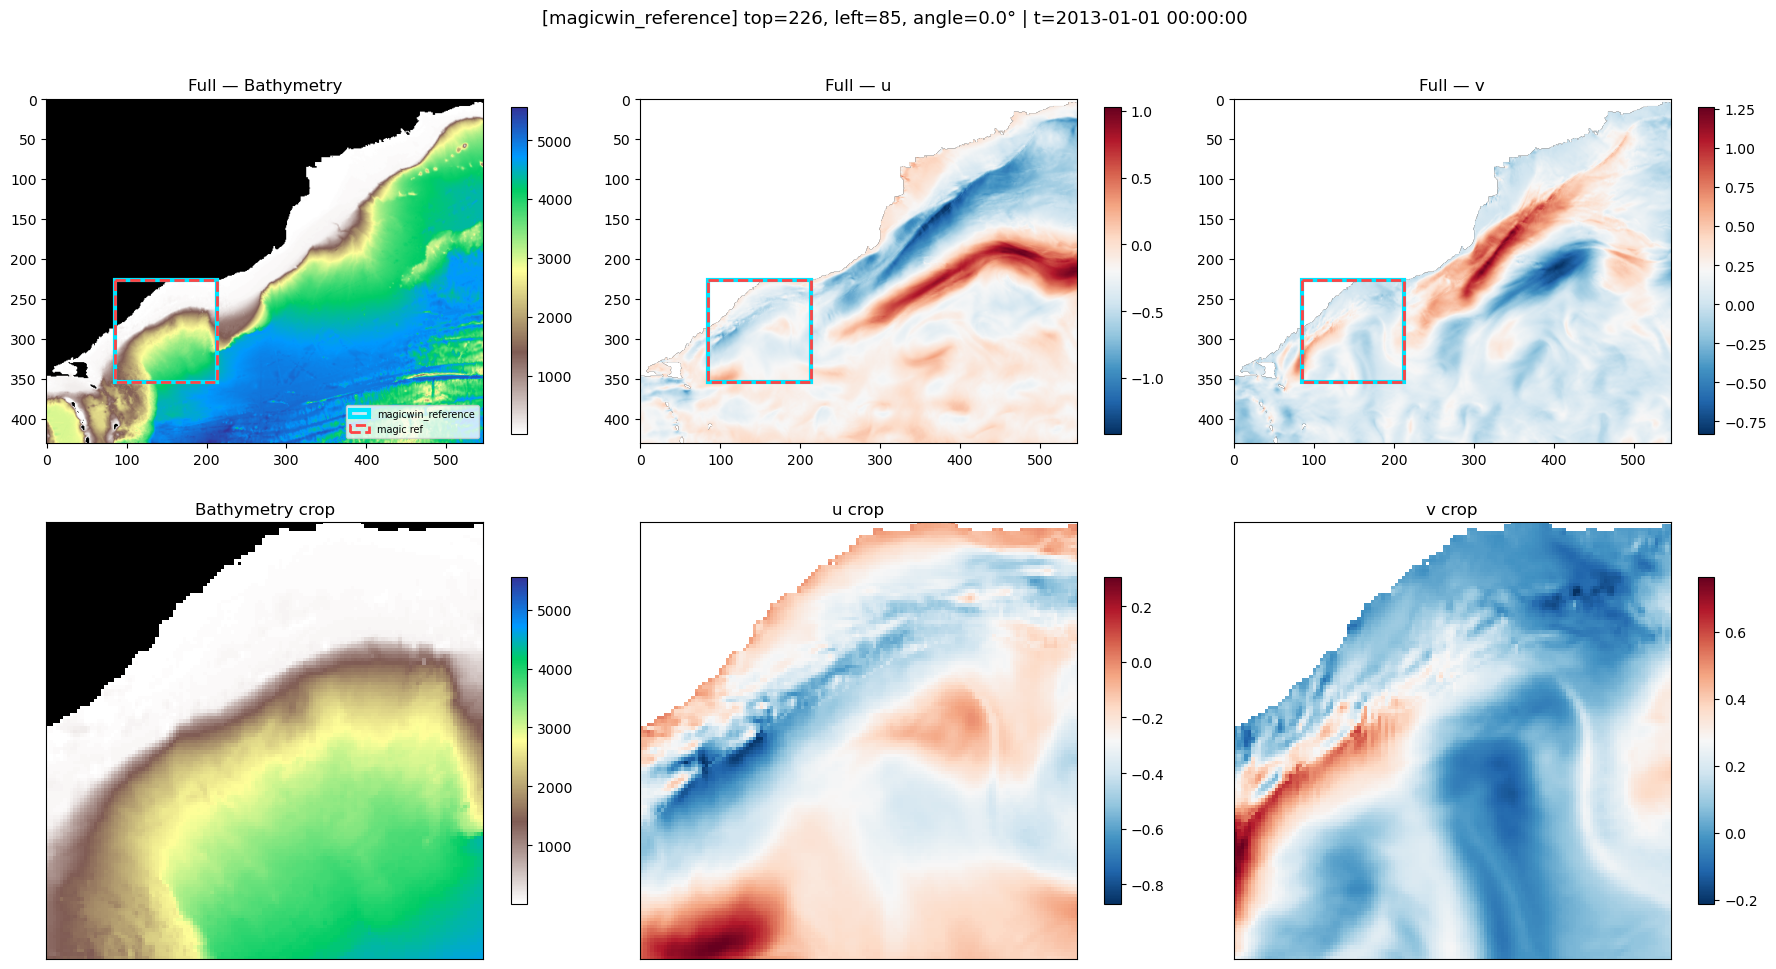

Saved window preview: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/data/magicwin_reference/window_preview.png


<Figure size 640x480 with 0 Axes>

In [2]:
%matplotlib inline
import importlib
import dynamic_dt.window_viz as _wv
importlib.reload(_wv)
from dynamic_dt.window_viz import preview_export_window

preview_dir = DATA_DIR / EXPORT_KEY
preview_dir.mkdir(parents=True, exist_ok=True)

WINDOW_SPEC = preview_export_window(
    EXPORT_KEY,
    time_idx=VIZ_TIME_IDX,
    save_path=preview_dir / "window_preview.png",
)

In [ ]:
common = dict(
    val_split=VAL_SPLIT,
    val_split_mode=VAL_SPLIT_MODE,
    val_split_seed=VAL_SPLIT_SEED,
    sample_seed=SEED,
    n_samples_to_gen=N_SAMPLES_TO_GEN,
    hour_of_day=HOUR_OF_DAY,
    detached=DETACHED,
    resume=RESUME,
    reuse_split=REUSE_SPLIT,
)

if EXPORT_ALL_DT:
    jobs = launch_export_sequential(
        dt_dir=DT_DIR,
        root=ROOT,
        export_key=EXPORT_KEY,
        zarr_path=ZARR_PATH,
        log_dir=LOG_DIR,
        dt_days_list=EXPORT_DT_DAYS_LIST,
        n_jobs_per_export=N_JOBS_PER_EXPORT,
        skip_finished=RESUME,
        **common,
    )
    print_job_summary(jobs, label="Export (sequential)")
else:
    summary = export_one_window(
        dt_dir=DT_DIR,
        root=ROOT,
        export_key=EXPORT_KEY,
        dt_days=DT_DAYS,
        zarr_path=ZARR_PATH,
        log_dir=LOG_DIR,
        n_jobs=N_JOBS_PER_EXPORT,
        **common,
    )
    print(f"\nDone: train={summary['n_train']} val={summary['n_val']}")
    print(f"  {summary['split_manifest']}")
    if summary.get("log_files"):
        for log_path in summary["log_files"]:
            print(f"  tail -f {log_path}")

Export plan — sequential, one dt at a time (4 dt values):
  dt=23d
  dt=25d
  dt=27d
  dt=30d

Export dt=23d (CPU, n_jobs=48)


  train uv n=2520
  Started PID 257821 → /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/data/magicwin_reference/sample_13_22_train_uv_dt552
  val uv n=1080
  Started PID 257822 → /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/data/magicwin_reference/sample_13_22_val_uv_dt552
  test 2023 uv n=249
  Started PID 258121 → /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/data/magicwin_reference/sample_23_uv_dt552
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 3 export(s)
  … waiting on 2 export(s)
  … waiting on 2 export(s)
  … waiting on 2 export(s)
  … waiting on 2 export(s)
  … w